<a href="https://colab.research.google.com/github/murilopdr/crd-public/blob/main/ML/02_predistorcao_ml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pré-distorção aprendida para OODN: semana 1, regressão linear

Substitui a pré-distorção por FFT do artigo por um **filtro FIR complexo de $K$ taps aprendido a partir de dados**, com o canal inalterado. Toda a física vem de `oodn_sim.py`; o aprendizado e a avaliação estão em `predist_ml.py`. Este notebook só roda os experimentos.

**Formulação: arquitetura de aprendizado indireto (ILA).** O canal é linear (MZM no regime linear seguido da fibra), então a ordem dos blocos não importa. Transmite-se OODN *sem* pré-distorção e treina-se um pós-inversor que, a partir de uma janela de $K$ amostras do campo na saída da fibra, estima a amostra transmitida no centro da janela:

$$\hat s[n] = \sum_{k=0}^{K-1} w_k\, E_\mathrm{rx}[n + k - c], \qquad c = (K-1)/2 .$$

Em forma matricial, $\hat{\mathbf s} = \mathbf X \mathbf w$: é **regressão linear complexa**, sem intercepto. O mesmo $\mathbf w$ é então usado como pré-distorcedor antes do MZM. O canal entra só como gerador de dados; nada exige um modelo diferenciável da fibra, o que vale também para o canal não linear da etapa seguinte.

**Custo:** $\mathrm{NMSE} = \overline{|\mathbf X\mathbf w - \mathbf y|^2} / \overline{|\mathbf y|^2}$. O gradiente em relação a $\mathbf w^*$ é $\mathbf X^H(\mathbf X\mathbf w - \mathbf y)/n$.

**Avaliação:** a métrica final é a BER, medida pela mesma cadeia, mesmas sementes e mesmo limiar da pré-distorção por FFT (`oodn_sim.varre(..., predistorcao=fir)`). Treino e teste usam sementes disjuntas entre si e das usadas na medição de BER.

## Ambiente

No Colab, a primeira célula clona o repositório e entra em `SUBPASTA` (token em *Secrets* como `GH_TOKEN`). Fora do Colab, ela não faz nada: abra o notebook com a pasta `ML/` como diretório de trabalho. `sync()` envia as edições dos arquivos do clone; rode antes de fechar a aba.

In [ ]:
import os, subprocess, sys

USER, REPO = "oodn-research", "oodn"        # organização e repositório
SUBPASTA = "ML"                             # pasta do notebook e dos modulos no repo

EM_COLAB = "google.colab" in sys.modules    # checa se está rodando no Colab
token = None
if EM_COLAB:
    from google.colab import userdata

    def segredo(nome):
        # Colab Secrets; se indisponivel, variavel de ambiente; por fim, pergunta
        try:
            return userdata.get(nome)
        except Exception as e:                 # TimeoutException, SecretNotFoundError, NotebookAccessError
            if os.environ.get(nome):
                return os.environ[nome]
            from getpass import getpass
            print(f"{nome} indisponivel em Secrets ({type(e).__name__}); digite o valor.")
            return getpass(f"{nome}: ")

    token = segredo("GH_TOKEN")
    NAME, EMAIL = segredo("GIT_NAME"), segredo("GIT_EMAIL")

    DIR = f"/content/{REPO}"
    if not os.path.isdir(DIR):
        subprocess.run(["git", "clone", "-q",
                        f"https://{token}@github.com/{USER}/{REPO}.git", DIR], check=True)
    else:
        subprocess.run(["git", "-C", DIR, "pull", "-q", "--rebase"], check=False)
    os.chdir(os.path.join(DIR, SUBPASTA))
    for k, v in (("user.name", NAME), ("user.email", EMAIL), ("pull.rebase", "true")):
        subprocess.run(["git", "config", k, v], check=True)

if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print("diretorio de trabalho:", os.getcwd())

def git(*args):
    r = subprocess.run(["git", *args], capture_output=True, text=True)
    out = r.stdout + r.stderr
    if token:
        out = out.replace(token, "***")          # nunca exibir o token
    if out.strip():
        print(out.strip())
    return r.returncode

def sync(msg="wip"):
    # Commit das edicoes locais, pull das do colega, push
    git("add", "-A")
    if git("diff", "--cached", "--quiet") != 0:
        git("commit", "-q", "-m", msg)
    if git("pull", "-q") != 0:
        git("rebase", "--abort")
        print("CONFLITO: o commit esta salvo localmente, mas NAO foi enviado. "
              "Resolva no github.dev antes de continuar.")
        return
    git("push", "-q")
    git("log", "--oneline", "-3")

diretorio de trabalho: /content/oodn/ML


## Parâmetros

A varredura em $K$ é a parte mais cara: uma cadeia óptica por $(L, K)$, cerca de 3–6 min no total com os valores padrão. `SIMBOLOS_BER` define a resolução da BER; com $10^5$ bits, o alvo $10^{-3}$ corresponde a cerca de 100 erros por ponto.

In [ ]:
RODAR_GD = True              # experimentos de gradiente descendente (rapidos)
RODAR_BER = True             # BER vs SNR em L_GD (5 cadeias)
RODAR_VARREDURA_K = True     # NMSE e SNR requerida vs K, para varios L (o mais caro)

L_GD = 50.0                  # km, usado nos experimentos de treino
K_GD = 61                    # taps nos experimentos de treino (impar)
N_LINHAS = 2**11             # linhas de treino e de teste (amostras), cada
SIMBOLOS_BER = 100_000       # bits por ponto de BER
ALVO_BER = 1e-3              # BER alvo para a SNR requerida

COMPRIMENTOS = (10.0, 50.0, 100.0)
KS = (1, 5, 11, 15, 21, 31, 43, 61, 87, 121, 181)

PASTA_SAIDA = "resultados/ml"   # figuras e tabelas

In [ ]:
# Contorno: o autoreload desta versao do IPython importa 'imp', removido no Python 3.12+
import sys, types, importlib
if "imp" not in sys.modules:
    imp_mock = types.ModuleType("imp")
    imp_mock.reload = importlib.reload
    sys.modules["imp"] = imp_mock

%load_ext autoreload
%autoreload 2
%matplotlib inline

import numpy as np
import scipy
import oodn_sim as sim
import predist_ml as ml

print(f"python {sys.version.split()[0]} | numpy {np.__version__} | scipy {scipy.__version__}")

cfg = sim.Config()
saida = lambda nome: os.path.join(PASTA_SAIDA, nome)
os.makedirs(PASTA_SAIDA, exist_ok=True)
deltas = np.arange(-10.0, 12.01, 0.5)      # grade fina: so o ruido muda entre pontos

python 3.13.18 | numpy 2.4.6 | scipy 1.16.3


## Dados

Treino e teste vêm de sinais independentes de 2048 símbolos ($1{,}3\times10^5$ amostras); de cada um sorteiam-se `N_LINHAS` janelas. As features são escalonadas com um único par $(\mu, \sigma)$ estimado no treino: todas as colunas são cópias atrasadas do mesmo sinal, então têm a mesma média e variância.

Os autovalores da hessiana $\mathbf X^H\mathbf X/n$ determinam a taxa de aprendizado estável e a velocidade de convergência do GD.

In [ ]:
cj = ml.monta_conjunto(cfg, L_GD, K_GD, N_LINHAS)
ev = ml.autovalores_hessiana(cj.Xtr)

print(f"L = {L_GD:g} km, K = {K_GD} | treino {cj.Xtr.shape}, teste {cj.Xte.shape}")
print(f"escala: mu = {cj.escala.mu:.3e}, sigma = {cj.escala.sigma:.3e}  (campo na saida da fibra, sqrt(W))")
print(f"hessiana: lambda_min = {ev.min():.3f}, lambda_max = {ev.max():.3f}, "
      f"condicionamento = {ev.max()/ev.min():.2f}")
print(f"taxa maxima estavel do GD em batelada: 2/lambda_max = {2/ev.max():.3f}")
print(f"taps de Savory: " + ", ".join(f"L = {L:g} km -> {ml.taps_savory(cfg, L)}" for L in COMPRIMENTOS))

L = 50 km, K = 61 | treino (32768, 61), teste (32768, 61)
escala: mu = -7.351e-05+4.274e-05j, sigma = 4.415e-03  (campo na saida da fibra, sqrt(W))
hessiana: lambda_min = 0.902, lambda_max = 1.114, condicionamento = 1.23
taxa maxima estavel do GD em batelada: 2/lambda_max = 1.796
taps de Savory: L = 10 km -> 9, L = 50 km -> 43, L = 100 km -> 87


**Leitura.** A OODN é ruído branco e a fibra é passa-tudo, então o campo recebido também é branco: as colunas de $\mathbf X$ são quase descorrelacionadas e a hessiana é próxima da identidade. O problema é muito bem condicionado, o que tem duas consequências: o GD em batelada com taxa próxima de 1 converge em poucas iterações, e a solução de mínimos quadrados é essencialmente a correlação cruzada entre entrada e alvo.

## Solução fechada: equação normal

$\mathbf w = (\mathbf X^H\mathbf X)^{-1}\mathbf X^H\mathbf y$. É a referência para todos os métodos iterativos. A figura compara os taps aprendidos com a resposta ao impulso do inversor ideal $H^*_\mathrm{fiber}$ truncada em $K$ taps, após ajustar um escalar complexo comum (a escala e a fase global não afetam a BER).

NMSE treino = -25.94 dB | teste = -25.63 dB
distancia relativa aos taps ideais truncados: 2.62e-03
-> resultados/ml/taps_aprendidos.png


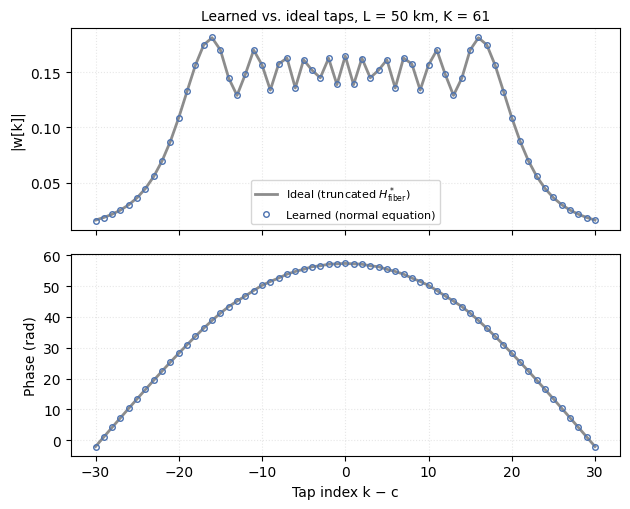

In [ ]:
w_ne = ml.equacao_normal(cj.Xtr, cj.ytr)
nmse_ne = ml.nmse(cj.Xtr, cj.ytr, w_ne)
w_id = ml.taps_ideais(cfg, L_GD, K_GD)
erro_forma = np.linalg.norm(ml.alinha(w_ne, w_id) - w_id) / np.linalg.norm(w_id)

print(f"NMSE treino = {ml.db(nmse_ne):.2f} dB | teste = {ml.db(ml.nmse(cj.Xte, cj.yte, w_ne)):.2f} dB")
print(f"distancia relativa aos taps ideais truncados: {erro_forma:.2e}")
ml.plota_taps(w_ne, w_id, f"Learned vs. ideal taps, L = {L_GD:g} km, K = {K_GD}",
              saida("taps_aprendidos.png"))

## Gradiente descendente em batelada

Mesmo problema, resolvido iterativamente com várias taxas de aprendizado. Acima de $2/\lambda_\mathrm{max}$ o GD diverge.

  lr = 0.1  NMSE final =   -25.55 dB
  lr = 0.5  NMSE final =   -25.94 dB
  lr = 1    NMSE final =   -25.94 dB
  lr = 1.7  NMSE final =   -25.93 dB
  lr = 1.9  NMSE final =    22.98 dB
-> resultados/ml/gd_batelada.png


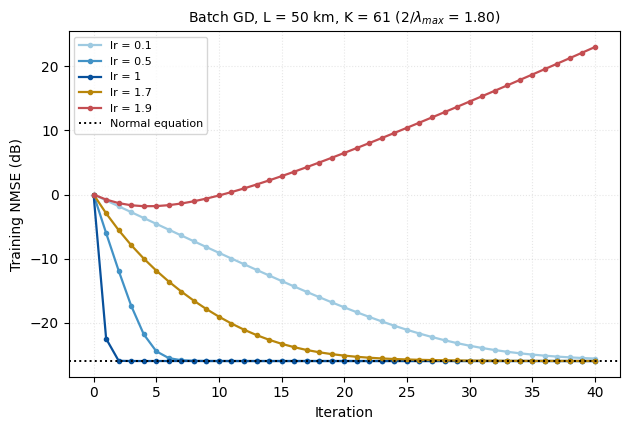

In [ ]:
if RODAR_GD:
    taxas = (0.1, 0.5, 1.0, 1.7, 1.9)
    hist_gd = {}
    for taxa in taxas:
        _, h = ml.gd_batelada(cj.Xtr, cj.ytr, taxa, 40)
        hist_gd[f"lr = {taxa:g}"] = h
        final = h["treino"][np.isfinite(h["treino"])][-1]
        print(f"  lr = {taxa:<4g} NMSE final = {ml.db(final):8.2f} dB")
    cores = dict(zip(hist_gd, ("#9ECAE1", "#4292C6", "#08519C", "#B8860B", "#C44E52")))
    ml.plota_curvas_gd(hist_gd, nmse_ne, "Iteration",
                       f"Batch GD, L = {L_GD:g} km, K = {K_GD} "
                       rf"($2/\lambda_{{max}}$ = {2/ev.max():.2f})",
                       saida("gd_batelada.png"), cores)

## Escalonamento das features

Sem escalonamento, o campo tem ordem de $10^{-3}\,\sqrt{\mathrm W}$ e os autovalores da hessiana caem para ordem de $10^{-5}$. Como todas as colunas têm a mesma escala, o condicionamento **não** muda: o que muda é a faixa útil de taxas. Uma taxa típica de dados escalonados não sai do lugar; a mesma taxa relativa a $\lambda_\mathrm{max}$ converge igual. A centralização remove a portadora residual do MZM (extinção finita), que sem intercepto o modelo não consegue representar.

sem escalonamento: lambda em [1.76e-05, 2.17e-05], condicionamento 1.24
  Scaled, lr = 1                     NMSE final =  -25.94 dB
  Unscaled, lr = 1                   NMSE final =   -0.01 dB
  Unscaled, lr = 1/$\lambda_{max}$   NMSE final =  -25.58 dB
-> resultados/ml/gd_escalonamento.png


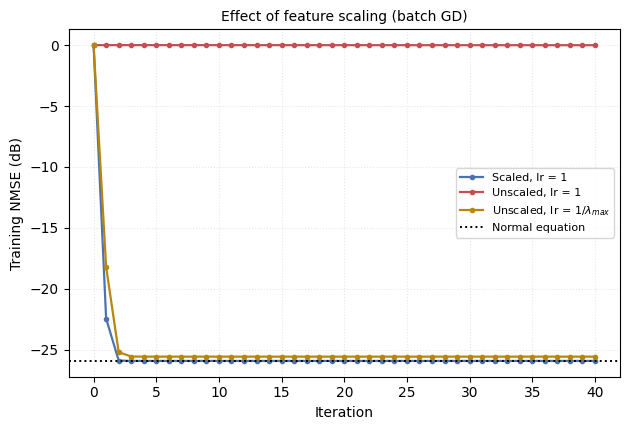

In [ ]:
if RODAR_GD:
    cu = ml.monta_conjunto(cfg, L_GD, K_GD, N_LINHAS, escalona=False)
    ev_u = ml.autovalores_hessiana(cu.Xtr)
    print(f"sem escalonamento: lambda em [{ev_u.min():.2e}, {ev_u.max():.2e}], "
          f"condicionamento {ev_u.max()/ev_u.min():.2f}")
    hist_esc = {
        "Scaled, lr = 1": ml.gd_batelada(cj.Xtr, cj.ytr, 1.0, 40)[1],
        "Unscaled, lr = 1": ml.gd_batelada(cu.Xtr, cu.ytr, 1.0, 40)[1],
        r"Unscaled, lr = 1/$\lambda_{max}$": ml.gd_batelada(cu.Xtr, cu.ytr, 1.0 / ev_u.max(), 40)[1],
    }
    for nome, h in hist_esc.items():
        print(f"  {nome:<34} NMSE final = {ml.db(h['treino'][-1]):7.2f} dB")
    cores = dict(zip(hist_esc, ("#4C72B0", "#C44E52", "#B8860B")))
    ml.plota_curvas_gd(hist_esc, nmse_ne, "Iteration", "Effect of feature scaling (batch GD)",
                       saida("gd_escalonamento.png"), cores)

## Minilotes e gradiente estocástico

Lote $B = 1$ é o SGD. A taxa usada para cada $B$ é metade do limite de estabilidade da hessiana amostral de um lote, $\lambda_\mathrm{max} \approx (1 + \sqrt{K/B})^2$, por isso o SGD precisa de uma taxa cerca de $K$ vezes menor que a batelada. Com taxa constante, o ruído do gradiente impõe um patamar acima da solução fechada; com taxa decrescente, $\eta_t = \eta_0/(1 + t/\tau)$, o SGD se aproxima dela.

  SGD (B = 1), constant lr   lr = 0.0129  NMSE treino =  -21.66 dB  teste =  -21.55 dB
  SGD (B = 1), decaying lr   lr = 0.0129  NMSE treino =  -25.92 dB  teste =  -25.61 dB
  Mini-batch, B = 32         lr = 0.1764  NMSE treino =  -24.27 dB  teste =  -24.13 dB
  Mini-batch, B = 1024       lr = 0.6461  NMSE treino =  -25.74 dB  teste =  -25.45 dB
-> resultados/ml/gd_minilote.png


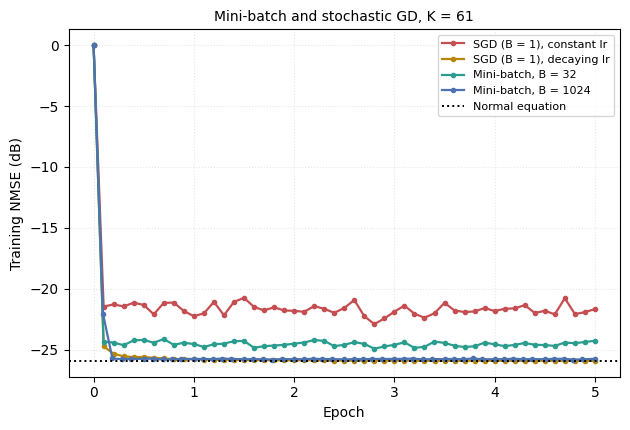

In [ ]:
if RODAR_GD:
    casos = (("SGD (B = 1), constant lr", 1, None),
             ("SGD (B = 1), decaying lr", 1, 2000.0),
             ("Mini-batch, B = 32", 32, None),
             ("Mini-batch, B = 1024", 1024, None))
    hist_mb = {}
    for nome, B, tau in casos:
        taxa = ml.taxa_segura(K_GD, B)
        _, h = ml.gd_minilote(cj.Xtr, cj.ytr, taxa, B, n_epocas=5, decaimento=tau,
                              Xte=cj.Xte, yte=cj.yte)
        hist_mb[nome] = h
        print(f"  {nome:<26} lr = {taxa:.4f}  NMSE treino = {ml.db(h['treino'][-1]):7.2f} dB"
              f"  teste = {ml.db(h['teste'][-1]):7.2f} dB")
    cores = dict(zip(hist_mb, ("#C44E52", "#B8860B", "#2A9D8F", "#4C72B0")))
    ml.plota_curvas_gd(hist_mb, nmse_ne, "Epoch", f"Mini-batch and stochastic GD, K = {K_GD}",
                       saida("gd_minilote.png"), cores)

## BER: FIR aprendido vs. pré-distorção por FFT

FIR treinado pela equação normal com $K$ igual ao número de Savory e com $K$ = `K_GD`, avaliado pela mesma cadeia, mesmas sementes e mesmo limiar ML do artigo. A curva teórica é a eq. (20), que, como visto antes, superestima a BER nessa faixa por causa da aproximação gaussiana sob $\mathcal H_1$.

  Uncompensated                    delta para BER = 1e-03:    nan dB
  FFT pre-distortion               delta para BER = 1e-03:  -0.81 dB
  Learned FIR, K = 43 (Savory)     delta para BER = 1e-03:  -0.76 dB
  Learned FIR, K = 61              delta para BER = 1e-03:  -0.81 dB
-> resultados/ml/ber_fir.png


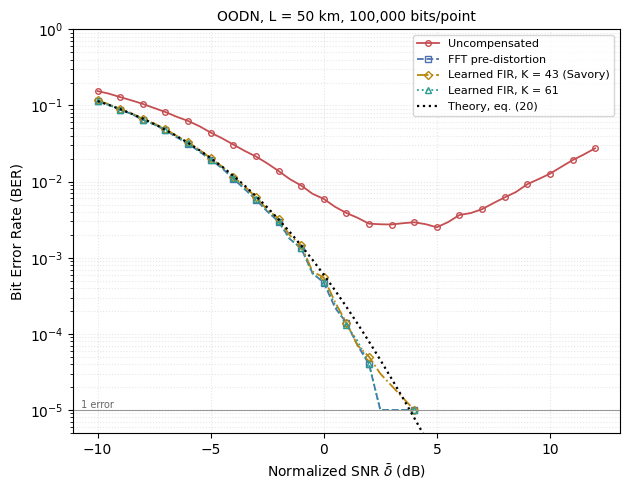

In [ ]:
if RODAR_BER:
    P_s_ref = sim.referencia_Ps(cfg, min(SIMBOLOS_BER, 50_000))
    K_sav = ml.taps_savory(cfg, L_GD)
    curvas_ber = {}
    for ref in ("uncomp", "predist"):
        curvas_ber[(L_GD, ref)] = sim.varre(cfg, L_GD, ref, deltas, SIMBOLOS_BER, P_s_ref)[0]
    for K in (K_sav, K_GD):
        cjK = ml.monta_conjunto(cfg, L_GD, K, N_LINHAS)
        wK = ml.equacao_normal(cjK.Xtr, cjK.ytr)
        curvas_ber[(L_GD, f"fir{K}")] = sim.varre(cfg, L_GD, "predist", deltas, SIMBOLOS_BER, P_s_ref,
                                                  predistorcao=ml.PreDistFIR(wK), rotulo=f"fir{K}")[0]
    nomes = {"uncomp": ("Uncompensated", ml.COR["uncomp"]),
             "predist": ("FFT pre-distortion", ml.COR["fft"]),
             f"fir{K_sav}": (f"Learned FIR, K = {K_sav} (Savory)", ml.COR["fir_a"]),
             f"fir{K_GD}": (f"Learned FIR, K = {K_GD}", ml.COR["fir_b"])}
    for chave, (rot, _) in nomes.items():
        print(f"  {rot:<32} delta para BER = {ALVO_BER:.0e}: "
              f"{ml.snr_requerida(curvas_ber[(L_GD, chave)], ALVO_BER):6.2f} dB")
    ml.plota_ber_fir(curvas_ber, L_GD, nomes, sim.curva_teorica(deltas, cfg.Nd),
                     f"OODN, L = {L_GD:g} km, {SIMBOLOS_BER:,} bits/point", saida("ber_fir.png"))

## Varredura em $K$

Para cada $L$ e $K$: treino pela equação normal, NMSE no conjunto de teste e a **penalidade de SNR em relação à pré-distorção por FFT** no mesmo $L$, medida na BER = `ALVO_BER` (0 dB = desempenho da FFT). Verticais pontilhadas: número de taps de Savory. Pontos ausentes no painel inferior são configurações que nunca atingem o alvo (patamar de BER acima dele).

  L =    10 km  K =    1  NMSE teste =   -0.49 dB  delta req. =  -0.63 dB
  L =    10 km  K =    5  NMSE teste =   -5.10 dB  delta req. =  -0.23 dB
  L =    10 km  K =   11  NMSE teste =  -17.58 dB  delta req. =  -0.83 dB
  L =    10 km  K =   15  NMSE teste =  -23.12 dB  delta req. =  -0.87 dB
  L =    10 km  K =   21  NMSE teste =  -28.12 dB  delta req. =  -0.86 dB
  L =    10 km  K =   31  NMSE teste =  -32.57 dB  delta req. =  -0.86 dB
  L =    10 km  K =   43  NMSE teste =  -34.98 dB  delta req. =  -0.87 dB
  L =    10 km  K =   61  NMSE teste =  -36.71 dB  delta req. =  -0.88 dB
  L =    10 km  K =   87  NMSE teste =  -37.16 dB  delta req. =  -0.88 dB
  L =    10 km  K =  121  NMSE teste =  -37.01 dB  delta req. =  -0.88 dB
  L =    10 km  K =  181  NMSE teste =  -37.33 dB  delta req. =  -0.88 dB
  L =    50 km  K =    1  NMSE teste =   -0.12 dB  delta req. =    nan dB
  L =    50 km  K =    5  NMSE teste =   -0.57 dB  delta req. =   2.61 dB
  L =    50 km  K =   11  NMSE teste =

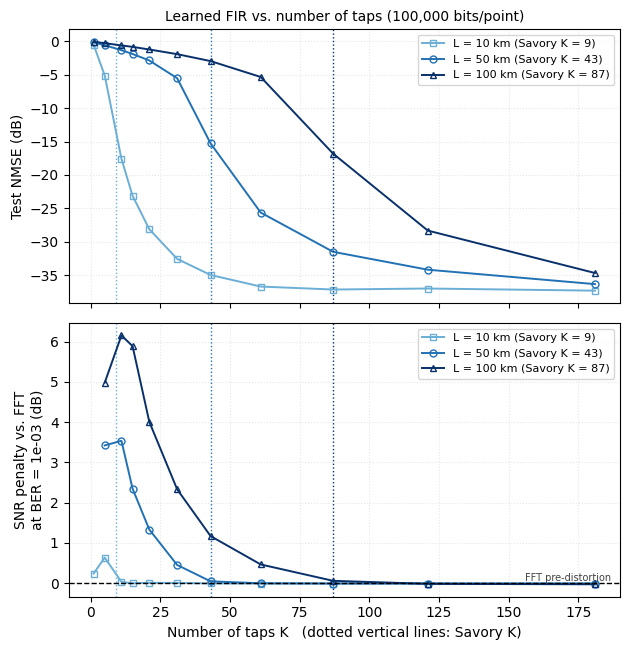

-> resultados/ml/varredura_K.dat  (K = 0: referencias; uncomp primeiro, FFT depois)


In [ ]:
if RODAR_VARREDURA_K:
    if not RODAR_BER:
        P_s_ref = sim.referencia_Ps(cfg, min(SIMBOLOS_BER, 50_000))
    tabela_K, curvas_K = ml.varre_K(cfg, COMPRIMENTOS, KS, P_s_ref, SIMBOLOS_BER, deltas,
                                    N_LINHAS, ALVO_BER)
    ml.plota_varredura_K(tabela_K, cfg, ALVO_BER,
                         f"Learned FIR vs. number of taps ({SIMBOLOS_BER:,} bits/point)",
                         saida("varredura_K.png"))

    pen = ml.penalidades(tabela_K)
    cab = "L_km K nmse_teste_dB delta_req_dB penalidade_dB t_treino_s"
    linhas = [[r["L_km"], r["K"], ml.db(r["nmse_te"]) if r["modelo"] == "fir" else np.nan,
               r["delta_req"], pen.get((r["L_km"], r["K"]), np.nan), r["t_treino_s"]]
              for r in tabela_K]
    np.savetxt(saida("varredura_K.dat"), np.array(linhas, dtype=float), header=cab,
               comments="", fmt="%.6g")
    print(f"-> {saida('varredura_K.dat')}  (K = 0: referencias; uncomp primeiro, FFT depois)")

## O que observar

- **Os taps aprendidos coincidem com o inversor ideal truncado.** Com entrada branca, o ótimo de mínimos quadrados para um FIR de $K$ taps é a resposta ao impulso ideal truncada; o aprendizado recupera essa forma sem conhecer $\beta_2$ nem $L$.
- **GD em batelada, minilotes e SGD convergem para a mesma solução** da equação normal, a menos do patamar do SGD com taxa constante. O problema é convexo e bem condicionado; a comparação entre otimizadores serve para validar o pipeline, não para escolher entre eles.
- **NMSE e BER discordam sobre quantos taps são necessários.** O detector integra a energia de cada símbolo, então erro de fase *dentro* do símbolo não custa nada; só a energia que vaza para os vizinhos importa. A BER satura perto do número de Savory, enquanto o NMSE ainda melhora muito acima dele. É um argumento para treinar com uma perda no domínio da energia, alinhada ao detector, na próxima etapa.
- **Com poucos taps, o ótimo em MSE não é o ótimo em BER.** Abaixo do número de Savory, a penalidade não cai de forma monótona com $K$, e um inverso truncado curto pode ser pior que nenhum. Minimizar o erro de campo não minimiza o vazamento de energia entre símbolos, que é o que o detector vê.